In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('../data/processed/df_clean.csv')

In [3]:
df.head()

,HG_Exp,AG_Exp,team_a_penalties_won,team_b_penalties_won,country,h_got_any_penalty,a_got_any_penalty,any_match_pen
0,1.53,1.18,0,0,eng1,0,0,0
1,1.82,0.62,1,0,eng1,1,0,1
2,1.52,1.27,0,0,eng1,0,0,0
3,1.31,1.53,0,0,eng1,0,0,0
4,0.92,1.79,0,0,eng1,0,0,0


In [4]:
print(df.shape)
print(df.columns.tolist())
display(df.head())

(164106, 8)
['HG_Exp', 'AG_Exp', 'team_a_penalties_won', 'team_b_penalties_won', 'country', 'h_got_any_penalty', 'a_got_any_penalty', 'any_match_pen']


,HG_Exp,AG_Exp,team_a_penalties_won,team_b_penalties_won,country,h_got_any_penalty,a_got_any_penalty,any_match_pen
0,1.53,1.18,0,0,eng1,0,0,0
1,1.82,0.62,1,0,eng1,1,0,1
2,1.52,1.27,0,0,eng1,0,0,0
3,1.31,1.53,0,0,eng1,0,0,0
4,0.92,1.79,0,0,eng1,0,0,0


In [5]:
print("Any-match penalty rate:")
print(df["any_match_pen"].mean().round(4))

print("\nTarget counts:")
print(df["any_match_pen"].value_counts())

print("\nMissing values:")
print(df[["HG_Exp", "AG_Exp", "country", "any_match_pen"]]
      .isna().sum())

print("\nPenalty rate by country:")
display(
    df.groupby("country")["any_match_pen"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

Any-match penalty rate:
0.2597

Target counts:
any_match_pen
0    121494
1     42612
Name: count, dtype: int64

Missing values:
HG_Exp           0
AG_Exp           0
country          0
any_match_pen    0
dtype: int64

Penalty rate by country:


,count,mean
country,,
fra1,5558,0.301907
ita1,6050,0.297190
spa1,5944,0.274899
ger1,4782,0.264325
other,135728,0.256822
eng1,6044,0.228326


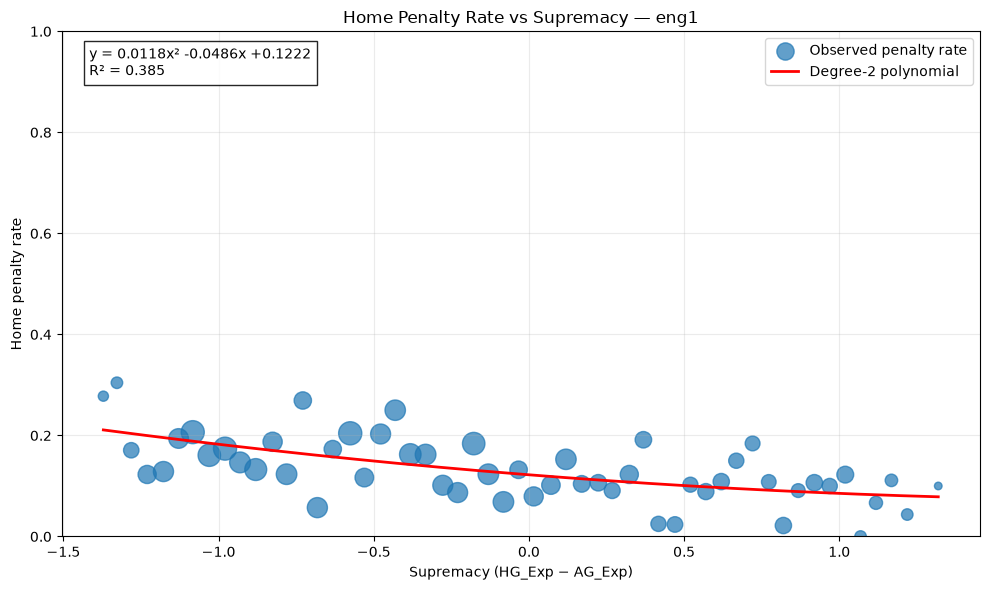

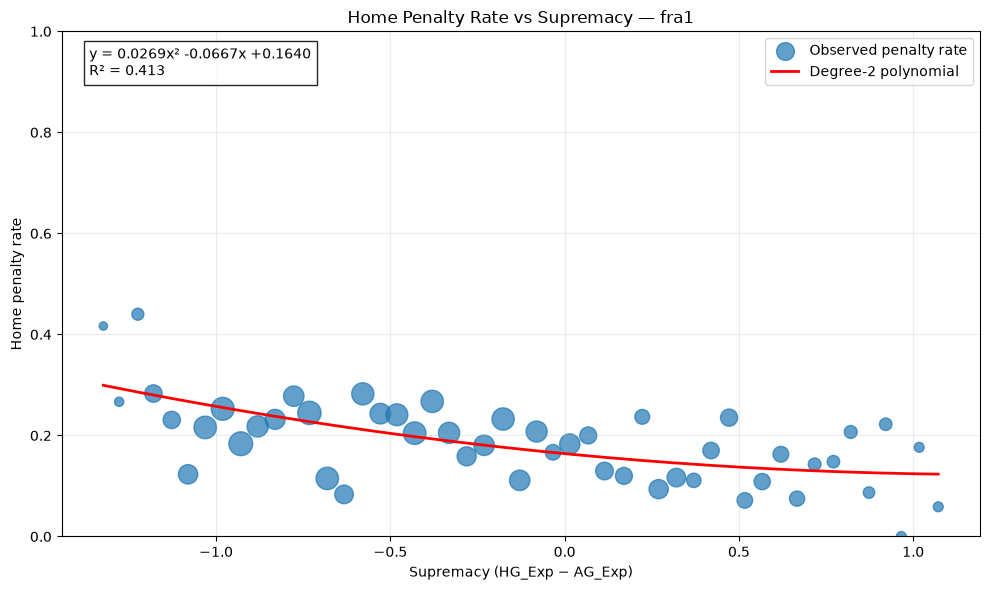

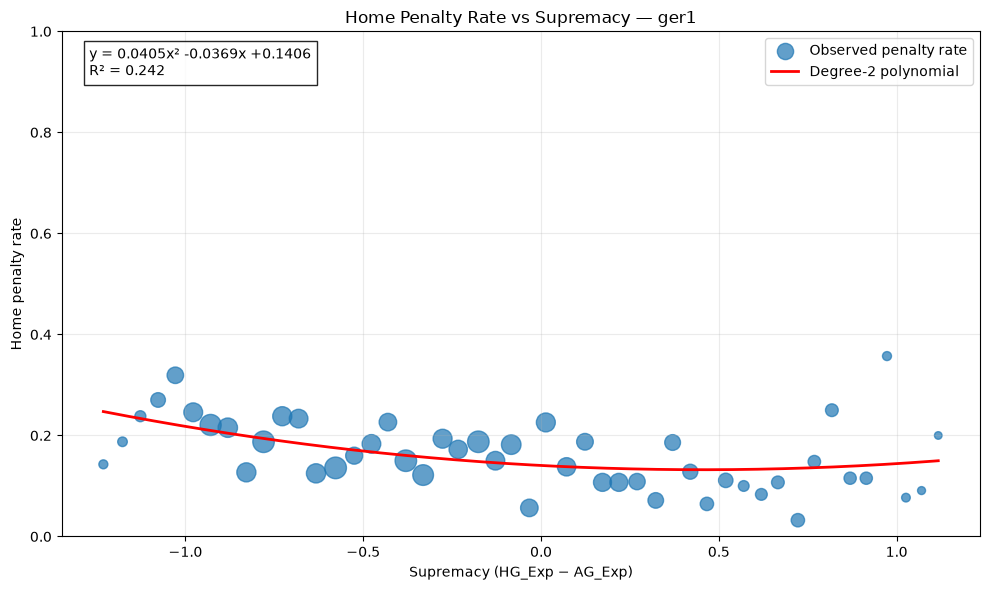

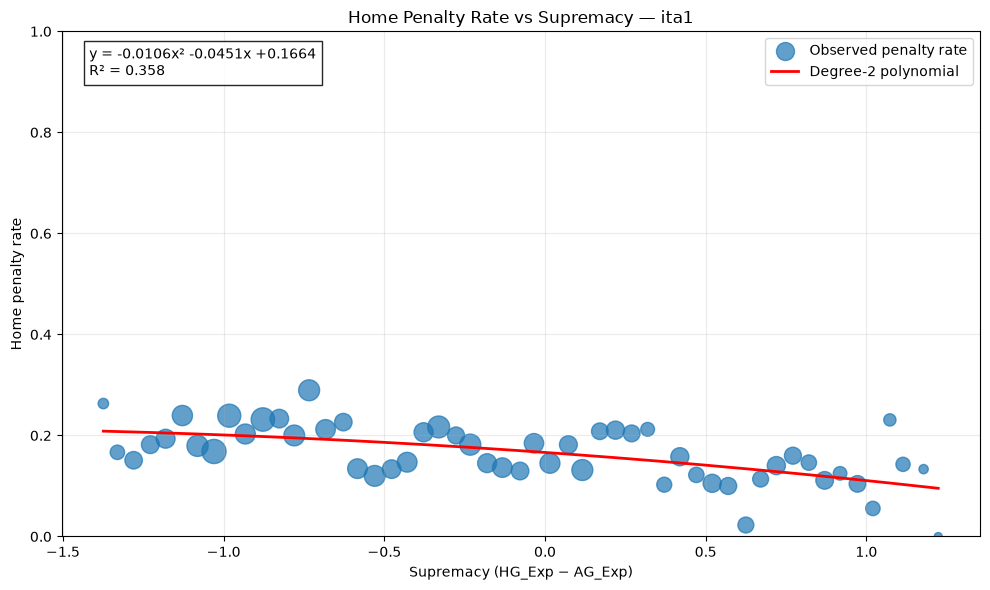

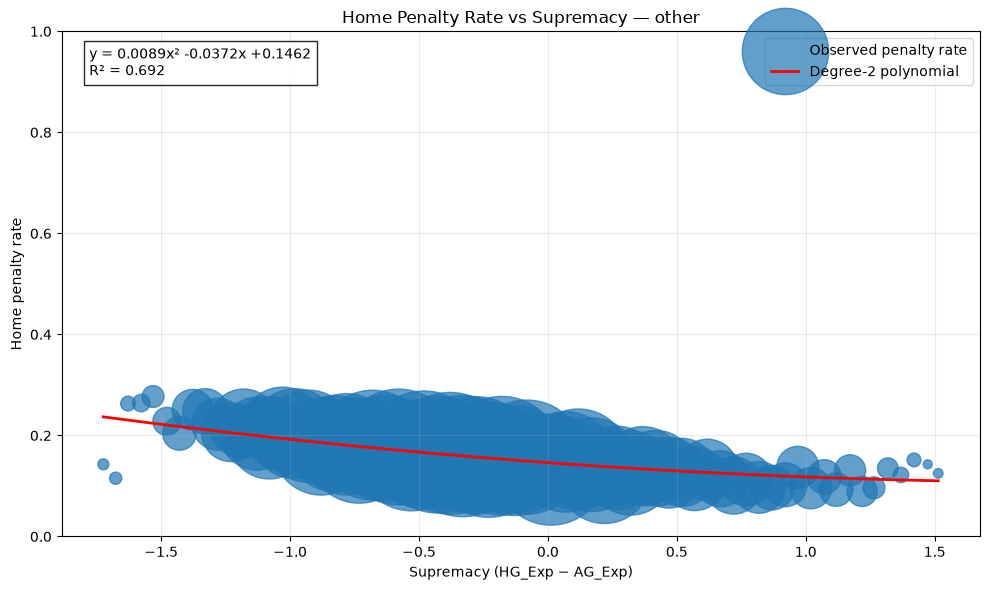

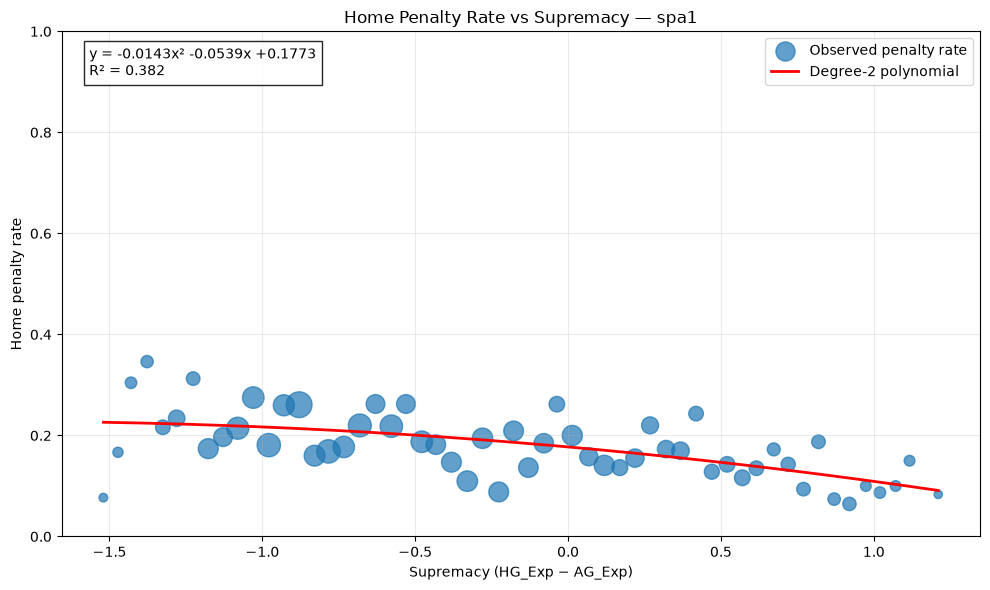

In [28]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate home-team supremacy
df["supremacy"] = df["HG_Exp"] - df["AG_Exp"]

# Bin supremacy in intervals of 0.05
bin_width = 0.05

bin_edges = np.arange(
    np.floor(df["supremacy"].min() / bin_width) * bin_width,
    np.ceil(df["supremacy"].max() / bin_width) * bin_width + bin_width,
    bin_width
)

df["supremacy_bin"] = pd.cut(
    df["supremacy"],
    bins=bin_edges,
    include_lowest=True
)

# Plot separately for each country
for country, data in df.groupby("country", observed=True):

    # Calculate penalty rate within each bin
    binned = (
        data.groupby("supremacy_bin", observed=True)
        .agg(
            supremacy=("supremacy", "mean"),
            penalty_rate=("h_got_any_penalty", "mean"),
            matches=("h_got_any_penalty", "size")
        )
        .reset_index(drop=True)
    )

    # Exclude bins with fewer than 30 matches
    binned = binned[binned["matches"] >= 20]

    if len(binned) < 3:
        print(f"Skipping {country}: fewer than 3 eligible bins")
        continue

    # Fit degree-2 polynomial: y = ax² + bx + c
    a, b, c = np.polyfit(
        binned["supremacy"],
        binned["penalty_rate"],
        2
    )

    # Calculate R² for the binned observations
    predicted = (
        a * binned["supremacy"]**2
        + b * binned["supremacy"]
        + c
    )

    ss_res = ((binned["penalty_rate"] - predicted) ** 2).sum()
    ss_tot = ((binned["penalty_rate"] - binned["penalty_rate"].mean()) ** 2).sum()

    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    # Generate smooth polynomial curve
    x_line = np.linspace(
        binned["supremacy"].min(),
        binned["supremacy"].max(),
        200
    )

    y_line = a * x_line**2 + b * x_line + c

    # Create plot
    fig, ax = plt.subplots(figsize=(10, 6))

    # Observed penalty rates; dot size reflects match count
    ax.scatter(
        binned["supremacy"],
        binned["penalty_rate"],
        s=binned["matches"] * 1.5,
        alpha=0.7,
        label="Observed penalty rate"
    )

    # Quadratic regression curve
    ax.plot(
        x_line,
        y_line,
        color="red",
        linewidth=2,
        label="Degree-2 polynomial"
    )

    # Equation and R²
    equation = (
        f"y = {a:.4f}x² {b:+.4f}x {c:+.4f}\n"
        f"R² = {r2:.3f}"
    )

    ax.text(
        0.03, 0.97,
        equation,
        transform=ax.transAxes,
        va="top",
        bbox=dict(facecolor="white", alpha=0.85)
    )

    ax.set_title(f"Home Penalty Rate vs Supremacy — {country}")
    ax.set_xlabel("Supremacy (HG_Exp − AG_Exp)")
    ax.set_ylabel("Home penalty rate")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()



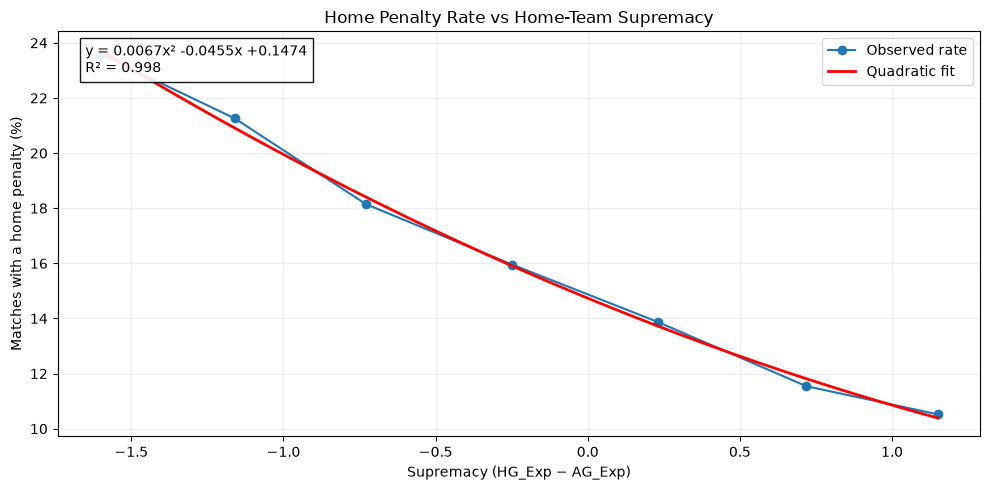

In [22]:


import numpy as np
import matplotlib.pyplot as plt

# Calculate supremacy
df["supremacy"] = df["HG_Exp"] - df["AG_Exp"]

# Bin supremacy in 0.5 intervals
bin_width = 0.5
edges = np.arange(
    np.floor(df["supremacy"].min() / bin_width) * bin_width,
    np.ceil(df["supremacy"].max() / bin_width) * bin_width + bin_width,
    bin_width
)

df["supremacy_bin"] = pd.cut(
    df["supremacy"], bins=edges, include_lowest=True
)

# Calculate observed rates
rates = (
    df.groupby("supremacy_bin", observed=True)
    .agg(
        x=("supremacy", "mean"),
        rate=("h_got_any_penalty", "mean"),
        n=("h_got_any_penalty", "size")
    )
    .reset_index(drop=True)
)

# Keep bins with enough matches
rates = rates[rates["n"] >= 100].copy()

# Quadratic fit
a, b, c = np.polyfit(rates["x"], rates["rate"], 2)
predicted = a * rates["x"]**2 + b * rates["x"] + c

ss_res = ((rates["rate"] - predicted) ** 2).sum()
ss_tot = ((rates["rate"] - rates["rate"].mean()) ** 2).sum()
r2 = 1 - ss_res / ss_tot if ss_tot else np.nan

x_line = np.linspace(rates["x"].min(), rates["x"].max(), 200)
y_line = a * x_line**2 + b * x_line + c

# Clean plot
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(rates["x"], rates["rate"] * 100,
        "o-", label="Observed rate")

ax.plot(x_line, y_line * 100, color="red",
        linewidth=2, label="Quadratic fit")

ax.set(
    title="Home Penalty Rate vs Home-Team Supremacy",
    xlabel="Supremacy (HG_Exp − AG_Exp)",
    ylabel="Matches with a home penalty (%)"
)

ax.text(
    0.03, 0.97,
    f"y = {a:.4f}x² {b:+.4f}x {c:+.4f}\nR² = {r2:.3f}",
    transform=ax.transAxes,
    va="top",
    bbox=dict(facecolor="white", alpha=0.9)
)

ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


In [23]:
df["supremacy"] = df["HG_Exp"] - df["AG_Exp"]

df["supremacy_group"] = pd.qcut(
    df["supremacy"],
    q=5,
    duplicates="drop"
)

display(
    df.groupby("supremacy_group", observed=True)
      .agg(
          matches=("h_got_any_penalty", "size"),
          avg_supremacy=("supremacy", "mean"),
          home_penalty_rate=("h_got_any_penalty", "mean")
      )
      .assign(
          home_penalty_pct=lambda x: (x["home_penalty_rate"] * 100).round(2)
      )
)

,matches,avg_supremacy,home_penalty_rate,home_penalty_pct
supremacy_group,,,,
"(-4.771, -0.8]",32922,-1.058174,0.202965,20.30
"(-0.8, -0.46]",33390,-0.619415,0.176520,17.65
"(-0.46, -0.16]",32348,-0.310032,0.161927,16.19
"(-0.16, 0.22]",33258,0.016355,0.146792,14.68
"(0.22, 4.56]",32188,0.611899,0.122282,12.23


In [24]:
df["supremacy"] = df["HG_Exp"] - df["AG_Exp"]

for country, data in df.groupby("country"):

    data = data.copy()

    data["supremacy_group"] = pd.qcut(
        data["supremacy"],
        q=5,
        duplicates="drop"
    )

    rates = (
        data.groupby("supremacy_group", observed=True)
        ["h_got_any_penalty"]
        .mean()
        .mul(100)
        .round(2)
    )

    print(f"\n{country}")
    display(rates.rename("Home penalty rate (%)").to_frame())


eng1


,Home penalty rate (%)
supremacy_group,
"(-1.781, -0.93]",17.13
"(-0.93, -0.49]",15.75
"(-0.49, -0.09]",15.84
"(-0.09, 0.48]",10.26
"(0.48, 1.57]",9.63



fra1


,Home penalty rate (%)
supremacy_group,
"(-1.581, -0.88]",23.20
"(-0.88, -0.52]",21.33
"(-0.52, -0.16]",21.43
"(-0.16, 0.31]",15.80
"(0.31, 1.3]",13.02



ger1


,Home penalty rate (%)
supremacy_group,
"(-4.771, -0.82]",21.49
"(-0.82, -0.45]",17.34
"(-0.45, -0.1]",17.57
"(-0.1, 0.35]",13.15
"(0.35, 4.56]",12.16


... (2 outputs left out)


other


,Home penalty rate (%)
supremacy_group,
"(-2.3009999999999997, -0.78]",20.15
"(-0.78, -0.45]",17.20
"(-0.45, -0.17]",16.03
"(-0.17, 0.19]",14.82
"(0.19, 2.71]",12.16



spa1


,Home penalty rate (%)
supremacy_group,
"(-1.9709999999999999, -0.96]",22.11
"(-0.96, -0.61]",21.45
"(-0.61, -0.2]",17.28
"(-0.2, 0.31]",18.21
"(0.31, 1.64]",13.47


In [25]:
# Recalculate supremacy from the home team's perspective
df["supremacy"] = df["HG_Exp"] - df["AG_Exp"]

# 1. Inspect actual rows
display(
    df[
        [
            "HG_Exp",
            "AG_Exp",
            "supremacy",
            "h_got_any_penalty",
            "a_got_any_penalty",
            "any_match_pen",
            "country",
        ]
    ].sample(10, random_state=42)
)

# 2. Check penalty flag values
for col in [
    "h_got_any_penalty",
    "a_got_any_penalty",
    "any_match_pen",
]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

# 3. Check whether the match flag agrees with either team's flag
expected_any = (
    (df["h_got_any_penalty"] == 1)
    | (df["a_got_any_penalty"] == 1)
).astype(int)

print(
    "\nRows where any_match_pen disagrees with the home/away flags:",
    (df["any_match_pen"] != expected_any).sum()
)

# 4. Compare penalty rates across supremacy groups
df["supremacy_group"] = pd.qcut(
    df["supremacy"], q=5, duplicates="drop"
)

display(
    df.groupby("supremacy_group", observed=True)
    .agg(
        matches=("supremacy", "size"),
        avg_supremacy=("supremacy", "mean"),
        home_penalty_rate=("h_got_any_penalty", "mean"),
        away_penalty_rate=("a_got_any_penalty", "mean"),
        any_penalty_rate=("any_match_pen", "mean"),
    )
    .mul(
        pd.Series({
            "matches": 1,
            "avg_supremacy": 1,
            "home_penalty_rate": 100,
            "away_penalty_rate": 100,
            "any_penalty_rate": 100,
        }),
        axis=1,
    )
    .round(2)
)

,HG_Exp,AG_Exp,supremacy,h_got_any_penalty,a_got_any_penalty,any_match_pen,country
57478,0.75,1.32,-0.57,0,0,0,other
145768,1.53,1.36,0.17,0,0,0,fra1
35223,0.83,1.70,-0.87,0,0,0,other
66785,1.20,2.00,-0.80,0,0,0,other
113492,1.76,1.62,0.14,0,0,0,other
8422,1.52,1.04,0.48,0,0,0,fra1
160588,1.09,1.75,-0.66,0,0,0,other
117870,1.27,1.83,-0.56,0,1,1,other
7475,0.75,1.91,-1.16,0,0,0,eng1
22450,0.60,2.00,-1.40,1,1,1,other



h_got_any_penalty:
h_got_any_penalty
0    137474
1     26632
Name: count, dtype: int64

a_got_any_penalty:
a_got_any_penalty
0    144238
1     19868
Name: count, dtype: int64

any_match_pen:
any_match_pen
0    121494
1     42612
Name: count, dtype: int64

Rows where any_match_pen disagrees with the home/away flags: 0


,matches,avg_supremacy,home_penalty_rate,away_penalty_rate,any_penalty_rate
supremacy_group,,,,,
"(-4.771, -0.8]",32922,-1.06,20.30,8.92,26.93
"(-0.8, -0.46]",33390,-0.62,17.65,10.07,25.43
"(-0.46, -0.16]",32348,-0.31,16.19,11.93,25.82
"(-0.16, 0.22]",33258,0.02,14.68,13.25,25.58
"(0.22, 4.56]",32188,0.61,12.23,16.47,26.08


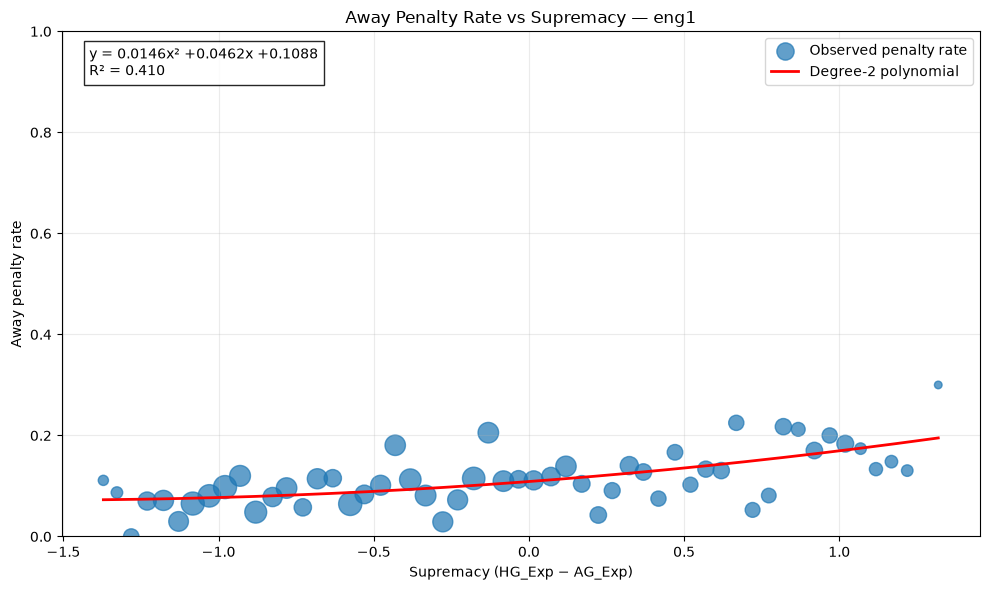

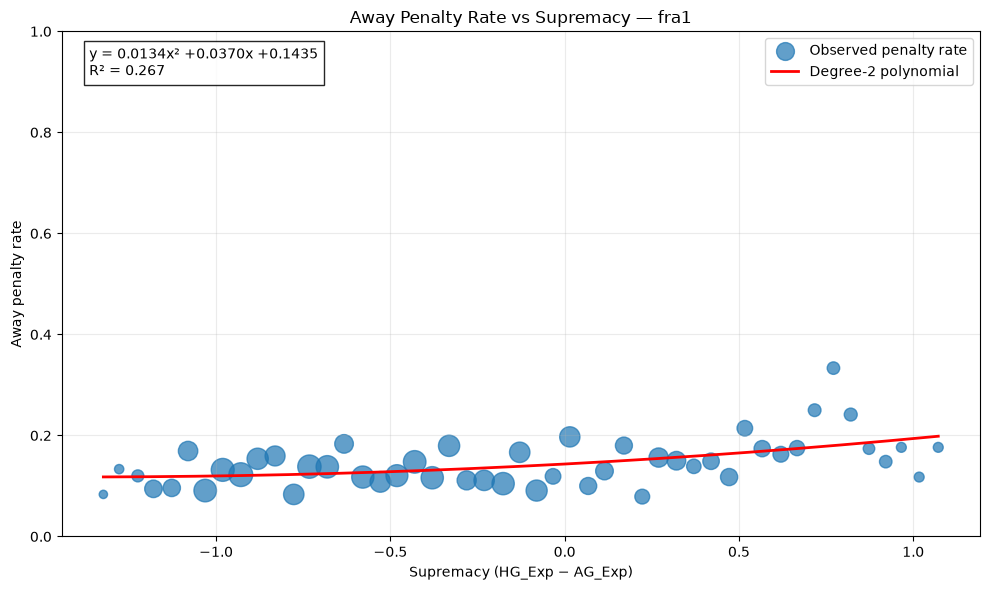

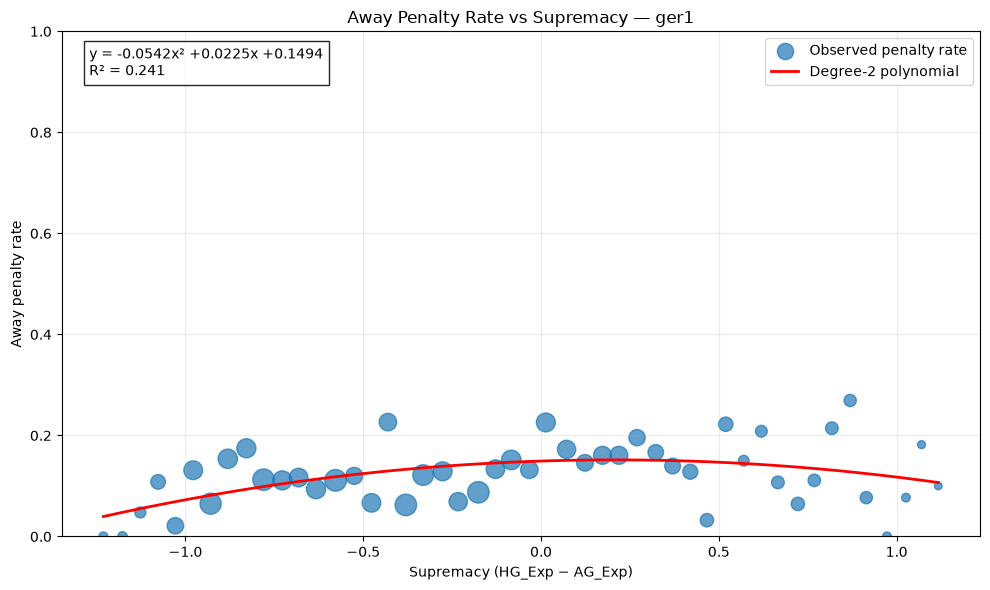

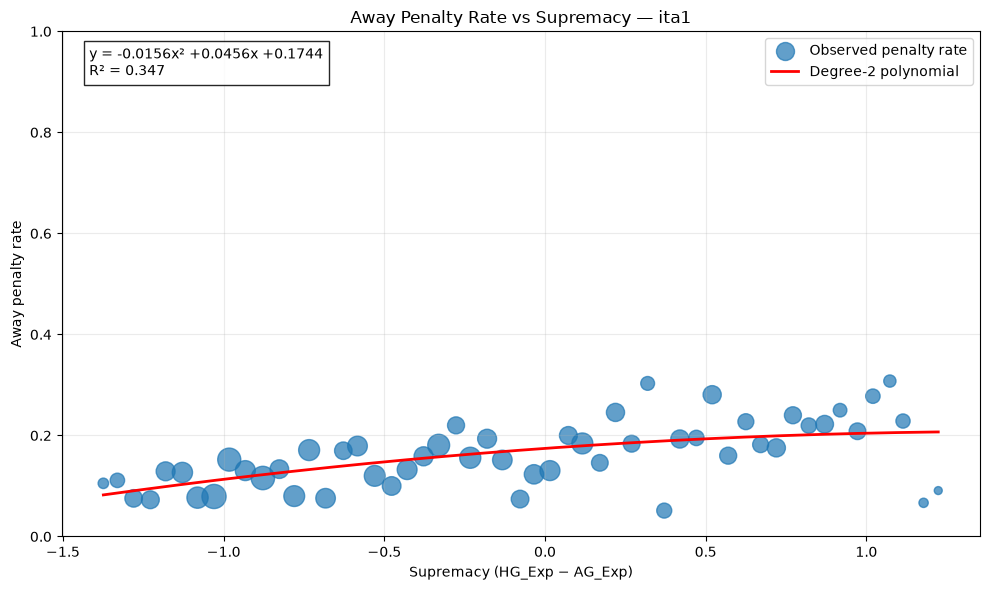

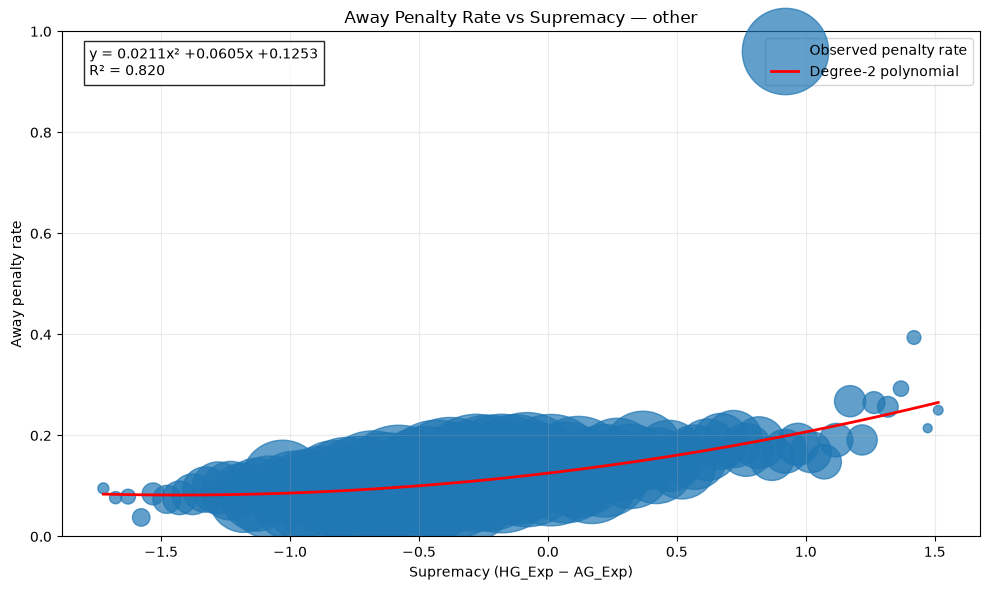

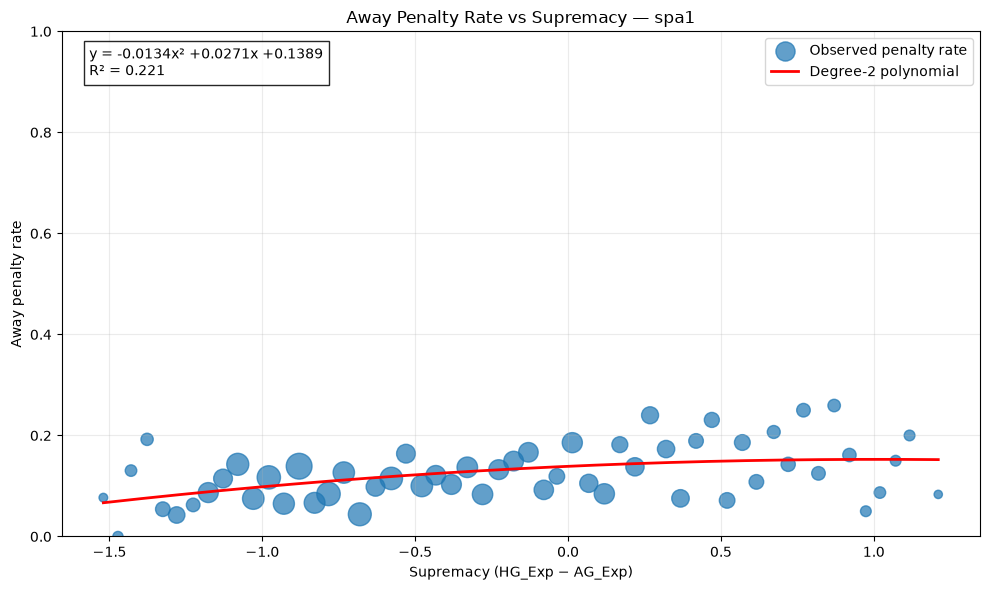

In [27]:
## AWAY

# Calculate home-team supremacy
df["supremacy"] = df["HG_Exp"] - df["AG_Exp"]

# Bin supremacy in intervals of 0.05
bin_width = 0.05

bin_edges = np.arange(
    np.floor(df["supremacy"].min() / bin_width) * bin_width,
    np.ceil(df["supremacy"].max() / bin_width) * bin_width + bin_width,
    bin_width
)

df["supremacy_bin"] = pd.cut(
    df["supremacy"],
    bins=bin_edges,
    include_lowest=True
)

# Plot separately for each country
for country, data in df.groupby("country", observed=True):

    # Calculate penalty rate within each bin
    binned = (
        data.groupby("supremacy_bin", observed=True)
        .agg(
            supremacy=("supremacy", "mean"),
            penalty_rate=("a_got_any_penalty", "mean"),
            matches=("a_got_any_penalty", "size")
        )
        .reset_index(drop=True)
    )

    # Exclude bins with fewer than 20 matches
    binned = binned[binned["matches"] >= 20]

    if len(binned) < 3:
        print(f"Skipping {country}: fewer than 3 eligible bins")
        continue

    # Fit degree-2 polynomial: y = ax² + bx + c
    a, b, c = np.polyfit(
        binned["supremacy"],
        binned["penalty_rate"],
        2
    )

    # Calculate R² for the binned observations
    predicted = (
        a * binned["supremacy"]**2
        + b * binned["supremacy"]
        + c
    )

    ss_res = ((binned["penalty_rate"] - predicted) ** 2).sum()
    ss_tot = ((binned["penalty_rate"] - binned["penalty_rate"].mean()) ** 2).sum()

    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    # Generate smooth polynomial curve
    x_line = np.linspace(
        binned["supremacy"].min(),
        binned["supremacy"].max(),
        200
    )

    y_line = a * x_line**2 + b * x_line + c

    # Create plot
    fig, ax = plt.subplots(figsize=(10, 6))

    # Observed penalty rates; dot size reflects match count
    ax.scatter(
        binned["supremacy"],
        binned["penalty_rate"],
        s=binned["matches"] * 1.5,
        alpha=0.7,
        label="Observed penalty rate"
    )

    # Quadratic regression curve
    ax.plot(
        x_line,
        y_line,
        color="red",
        linewidth=2,
        label="Degree-2 polynomial"
    )

    # Equation and R²
    equation = (
        f"y = {a:.4f}x² {b:+.4f}x {c:+.4f}\n"
        f"R² = {r2:.3f}"
    )

    ax.text(
        0.03, 0.97,
        equation,
        transform=ax.transAxes,
        va="top",
        bbox=dict(facecolor="white", alpha=0.85)
    )

    ax.set_title(f"Away Penalty Rate vs Supremacy — {country}")
    ax.set_xlabel("Supremacy (HG_Exp − AG_Exp)")
    ax.set_ylabel("Away penalty rate")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()